In [1]:
# define the standard library for machine learning
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# define the machine learning model (regression tree)
from sklearn.tree import DecisionTreeRegressor

# define the model selection and evaluation libraries
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

In [2]:
%pip install "xlrd>=2.0.1"


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_excel(
    "Scats Data October 2006.xls",
    sheet_name="Data",
    header=1
)

In [4]:
# check the data information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4192 entries, 0 to 4191
Columns: 106 entries, SCATS Number to V95
dtypes: datetime64[us](1), float64(2), int64(101), str(2)
memory usage: 3.4 MB


In [5]:
df[["SCATS Number", "Location", "Date", "V00", "V01", "V02"]].head()

,SCATS Number,Location,Date,V00,V01,V02
0,970,WARRIGAL_RD N of HIGH STREET_RD,2006-10-01 00:15:00,86,83,52
1,970,WARRIGAL_RD N of HIGH STREET_RD,2006-10-02 00:15:00,32,28,17
2,970,WARRIGAL_RD N of HIGH STREET_RD,2006-10-03 00:15:00,26,32,21
3,970,WARRIGAL_RD N of HIGH STREET_RD,2006-10-04 00:15:00,32,22,28
4,970,WARRIGAL_RD N of HIGH STREET_RD,2006-10-05 00:15:00,40,39,21


In [6]:
# Use the location shown in the first row.
location = df["Location"].iloc[0]

# Keep only the date and the first 15-minute traffic count.
traffic = df.loc[df["Location"] == location, ["Date", "V00"]]
traffic.sort_values("Date").head(10)

,Date,V00
0,2006-10-01 00:15:00,86
1,2006-10-02 00:15:00,32
2,2006-10-03 00:15:00,26
3,2006-10-04 00:15:00,32
4,2006-10-05 00:15:00,40
5,2006-10-06 00:15:00,36
6,2006-10-07 00:15:00,62
7,2006-10-08 00:15:00,116
8,2006-10-09 00:15:00,23
9,2006-10-10 00:15:00,27


In [7]:
# Take the first five traffic counts from one location on one day.
columns = ["V00", "V01", "V02", "V03", "V04"]
counts = df.loc[0, columns].to_numpy(dtype=float)

# Use four consecutive counts to predict the fifth.
X = counts[:4]
y = counts[4]

print("Input (X):", X)
print("Actual next count (y):", y)

Input (X): [86. 83. 52. 58.]
Actual next count (y): 59.0


In [8]:
# Read all 96 traffic counts from the first row.
volume_columns = [f"V{i:02d}" for i in range(96)]
counts = df.loc[0, volume_columns].to_numpy(dtype=float)

window_size = 4
X_samples = []
y_samples = []

# Move the window one time slot at a time.
for start in range(len(counts) - window_size):
    end = start + window_size
    X_samples.append(counts[start:end])
    y_samples.append(counts[end])

print("Number of samples:", len(X_samples))

for i in range(3):
    print(f"Sample {i + 1}: X = {X_samples[i]}, y = {y_samples[i]}")

Number of samples: 92
Sample 1: X = [86. 83. 52. 58.], y = 59.0
Sample 2: X = [83. 52. 58. 59.], y = 44.0
Sample 3: X = [52. 58. 59. 44.], y = 31.0


In [9]:
import numpy as np

# Select all dates for the location in the first row.
same_location = (
    (df["SCATS Number"] == df.loc[0, "SCATS Number"])
    & (df["Location"] == df.loc[0, "Location"])
)
daily_traffic = df.loc[same_location].sort_values("Date")

X_all = []
y_all = []

# Create samples separately for each day.
for day_counts in daily_traffic[volume_columns].to_numpy(dtype=float):
    for start in range(len(day_counts) - window_size):
        end = start + window_size
        X_all.append(day_counts[start:end])
        y_all.append(day_counts[end])

# LSTM input shape: samples, time steps, features.
X_all = np.array(X_all)[..., np.newaxis]
y_all = np.array(y_all)

print("Number of daily records:", len(daily_traffic))
print("X shape:", X_all.shape)
print("y shape:", y_all.shape)

Number of daily records: 31
X shape: (2852, 4, 1)
y shape: (2852,)


In [10]:
# Keep the first 24 days for training and the last 7 for testing.
train_days = 24
samples_per_day = len(volume_columns) - window_size
split_index = train_days * samples_per_day

# Split the inputs and their matching targets at the same point.
X_train_lstm = X_all[:split_index]
y_train_lstm = y_all[:split_index]

X_test_lstm = X_all[split_index:]
y_test_lstm = y_all[split_index:]

print("Training:", X_train_lstm.shape, y_train_lstm.shape)
print("Testing:", X_test_lstm.shape, y_test_lstm.shape)
print("Last training date:", daily_traffic["Date"].iloc[train_days - 1].date())
print("First testing date:", daily_traffic["Date"].iloc[train_days].date())

Training: (2208, 4, 1) (2208,)
Testing: (644, 4, 1) (644,)
Last training date: 2006-10-24
First testing date: 2006-10-25


In [11]:
# Get the scaling range from training data only.
traffic_min = min(X_train_lstm.min(), y_train_lstm.min())
traffic_max = max(X_train_lstm.max(), y_train_lstm.max())
traffic_range = traffic_max - traffic_min

# Apply the same scale to both training and testing data.
X_train_scaled = (X_train_lstm - traffic_min) / traffic_range
y_train_scaled = (y_train_lstm - traffic_min) / traffic_range
X_test_scaled = (X_test_lstm - traffic_min) / traffic_range
y_test_scaled = (y_test_lstm - traffic_min) / traffic_range

print("Training traffic range:", traffic_min, "to", traffic_max)
print("First input before scaling:", X_train_lstm[0, :, 0])
print("First input after scaling:", X_train_scaled[0, :, 0])
print("Training input shape:", X_train_scaled.shape)

Training traffic range: 1.0 to 450.0
First input before scaling: [86. 83. 52. 58.]
First input after scaling: [0.18930958 0.18262806 0.11358575 0.12694878]
Training input shape: (2208, 4, 1)


In [12]:
%pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dense

# Read four time steps with one traffic count per step.
model = Sequential([
    Input(shape=(4, 1)),
    LSTM(16),
    Dense(1),
])

# Train the model to predict the next traffic count.
model.compile(optimizer="adam", loss="mse")
model.fit(X_train_scaled, y_train_scaled, epochs=5, batch_size=32)

Epoch 1/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 568us/step - loss: 0.0990 
Epoch 2/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 441us/step - loss: 0.0163
Epoch 3/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - loss: 0.0100
Epoch 4/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step - loss: 0.0081
Epoch 5/5
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 423us/step - loss: 0.0078


In [14]:
import numpy as np

# Predict the next traffic count for each test sample.
predicted_scaled = model.predict(X_test_scaled, verbose=0).ravel()

# Convert the predictions back to vehicle counts.
predicted_traffic = predicted_scaled * traffic_range + traffic_min

# Compare predictions with the actual traffic counts.
errors = predicted_traffic - y_test_lstm
rmse = np.sqrt(np.mean(errors ** 2))
nrmse = rmse / np.mean(y_test_lstm)

print(f"Test samples: {len(predicted_traffic)}")
print(f"Test RMSE: {rmse:.2f} vehicles")
print(f"Test NRMSE: {nrmse:.2%}")

# Show the first five predictions and actual counts.
for i in range(5):
    print(f"Sample {i + 1}: predicted {predicted_traffic[i]:.1f}, actual {y_test_lstm[i]:.0f}")

Test samples: 644
Test RMSE: 39.95 vehicles
Test NRMSE: 20.24%
Sample 1: predicted 39.8, actual 11
Sample 2: predicted 35.6, actual 9
Sample 3: predicted 30.9, actual 16
Sample 4: predicted 29.4, actual 11
Sample 5: predicted 28.1, actual 9


In [15]:
# Use the last observed count to predict the next count.
baseline_predictions = X_test_lstm[:, -1, 0]

# Compare both methods on the same 644 test samples.
baseline_errors = baseline_predictions - y_test_lstm
baseline_rmse = np.sqrt(np.mean(baseline_errors ** 2))

print(f"LSTM RMSE:     {rmse:.2f} vehicles")
print(f"Baseline RMSE: {baseline_rmse:.2f} vehicles")

LSTM RMSE:     39.95 vehicles
Baseline RMSE: 30.68 vehicles


In [16]:
# Use October 1–20 for training and October 21–24 for validation.
fit_end = 20 * samples_per_day

X_fit = X_train_lstm[:fit_end]
y_fit = y_train_lstm[:fit_end]

X_val = X_train_lstm[fit_end:]
y_val = y_train_lstm[fit_end:]

print("Training:", X_fit.shape, y_fit.shape)
print("Validation:", X_val.shape, y_val.shape)

Training: (1840, 4, 1) (1840,)
Validation: (368, 4, 1) (368,)


In [17]:
from tensorflow.keras.callbacks import EarlyStopping

# Calculate the scaling range using only the first 20 days.
fit_min = min(X_fit.min(), y_fit.min())
fit_max = max(X_fit.max(), y_fit.max())
fit_range = fit_max - fit_min

X_fit_scaled = (X_fit - fit_min) / fit_range
y_fit_scaled = (y_fit - fit_min) / fit_range
X_val_scaled = (X_val - fit_min) / fit_range
y_val_scaled = (y_val - fit_min) / fit_range

# Train a fresh LSTM with the same architecture.
validated_model = Sequential([
    Input(shape=(4, 1)),
    LSTM(16),
    Dense(1),
])
validated_model.compile(optimizer="adam", loss="mse")

# Stop after five epochs without improvement and restore the best weights.
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = validated_model.fit(
    X_fit_scaled,
    y_fit_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
)

best_epoch = np.argmin(history.history["val_loss"]) + 1
print(f"Best validation epoch: {best_epoch}")
print(f"Best validation loss: {min(history.history['val_loss']):.5f}")

Epoch 1/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1110 - val_loss: 0.0192
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step - loss: 0.0172 - val_loss: 0.0126
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step - loss: 0.0117 - val_loss: 0.0088
Epoch 4/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step - loss: 0.0094 - val_loss: 0.0075
Epoch 5/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step - loss: 0.0087 - val_loss: 0.0072
Epoch 6/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 680us/step - loss: 0.0085 - val_loss: 0.0070
Epoch 7/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 708us/step - loss: 0.0084 - val_loss: 0.0069
Epoch 8/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - loss: 0.0082 - val_loss: 0.0068
Epoch 9/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 651us/step - loss: 0.0081 - val_loss: 0.0067
Epoch 10/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step - loss: 0.0080 - val_loss: 0.0066
Epoch 11/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 663us/step - loss: 0.0079 - val_loss: 0.0065
Epoch 12/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step -

In [18]:
# Scale the raw test inputs using the range fitted on October 1–20.
X_test_validated = (X_test_lstm - fit_min) / fit_range

# Predict and convert back to vehicle counts.
predictions_scaled = validated_model.predict(X_test_validated, verbose=0).ravel()
predictions = predictions_scaled * fit_range + fit_min

# Evaluate against the actual counts on the same test samples.
test_errors = predictions - y_test_lstm
validated_rmse = np.sqrt(np.mean(test_errors ** 2))
validated_nrmse = validated_rmse / np.mean(y_test_lstm)

print(f"Test samples: {len(predictions)}")
print(f"First LSTM RMSE:     {rmse:.2f} vehicles")
print(f"Validated LSTM RMSE: {validated_rmse:.2f} vehicles")
print(f"Baseline RMSE:       {baseline_rmse:.2f} vehicles")
print(f"Validated LSTM NRMSE: {validated_nrmse:.2%}")

Test samples: 644
First LSTM RMSE:     39.95 vehicles
Validated LSTM RMSE: 31.71 vehicles
Baseline RMSE:       30.68 vehicles
Validated LSTM NRMSE: 16.07%


In [19]:
# Reload the original sheet so the SCATS and location columns are available.
traffic_df = pd.read_excel(
    "Scats Data October 2006.xls",
    sheet_name="Data",
    header=1,
)

# Count the distinct dates for each measurement location.
site_locations = (
    traffic_df.groupby(["SCATS Number", "Location"])["Date"]
    .nunique()
    .reset_index(name="Days recorded")
)

print("SCATS sites:", site_locations["SCATS Number"].nunique())
print("Measurement locations:", len(site_locations))
display(site_locations.head(10))

SCATS sites: 40
Measurement locations: 139


,SCATS Number,Location,Days recorded
0,970,HIGH STREET_RD E of WARRIGAL_RD,31
1,970,HIGH STREET_RD W of WARRIGAL_RD,30
2,970,WARRIGAL_RD N of HIGH STREET_RD,31
3,970,WARRIGAL_RD S of HIGH STREET_RD,31
4,2000,BURWOOD_HWY E of WARRIGAL_RD,29
5,2000,TOORAK_RD W of WARRIGAL_RD,29
6,2000,WARRIGAL_RD N of TOORAK_RD,28
7,2000,WARRIGAL_RD S of BURWOOD_HWY,28
8,2200,MAROONDAH_HWY E of UNION_RD,31
9,2200,MAROONDAH_HWY W of UNION_RD,31


In [20]:
def make_location_samples(site_number, location_name):
    # Select one measurement location and sort its records by date.
    matching_rows = (
        (traffic_df["SCATS Number"] == site_number)
        & (traffic_df["Location"] == location_name)
    )
    records = traffic_df.loc[matching_rows].sort_values("Date")

    if records.empty:
        raise ValueError("No records found for this site and location.")

    inputs = []
    targets = []
    sample_dates = []

    # Build windows within each day's record.
    for _, row in records.iterrows():
        counts = row[volume_columns].to_numpy(dtype=float)

        for start in range(len(counts) - window_size):
            end = start + window_size
            inputs.append(counts[start:end])
            targets.append(counts[end])
            sample_dates.append(row["Date"])

    # Keep one date per sample so we can split by calendar date.
    X = np.array(inputs)[..., np.newaxis]
    y = np.array(targets)
    return X, y, pd.DatetimeIndex(sample_dates)


X_2200, y_2200, dates_2200 = make_location_samples(
    2200,
    "MAROONDAH_HWY E of UNION_RD",
)

print("Days recorded:", dates_2200.normalize().nunique())
print("X shape:", X_2200.shape)
print("y shape:", y_2200.shape)

Days recorded: 31
X shape: (2852, 4, 1)
y shape: (2852,)


In [21]:
# Split the samples by calendar date.
validation_start = pd.Timestamp("2006-10-21")
test_start = pd.Timestamp("2006-10-25")

train_mask = dates_2200 < validation_start
val_mask = (dates_2200 >= validation_start) & (dates_2200 < test_start)
test_mask = dates_2200 >= test_start

X_train, y_train = X_2200[train_mask], y_2200[train_mask]
X_val_2200, y_val_2200 = X_2200[val_mask], y_2200[val_mask]
X_test, y_test = X_2200[test_mask], y_2200[test_mask]

# Fit the scaling range on this location's training data.
min_2200 = min(X_train.min(), y_train.min())
max_2200 = max(X_train.max(), y_train.max())
range_2200 = max_2200 - min_2200

X_train_scaled_2200 = (X_train - min_2200) / range_2200
y_train_scaled_2200 = (y_train - min_2200) / range_2200
X_val_scaled_2200 = (X_val_2200 - min_2200) / range_2200
y_val_scaled_2200 = (y_val_2200 - min_2200) / range_2200

# Train a fresh LSTM with the same architecture as site 970.
model_2200 = Sequential([Input(shape=(4, 1)), LSTM(16), Dense(1)])
model_2200.compile(optimizer="adam", loss="mse")
model_2200.fit(
    X_train_scaled_2200,
    y_train_scaled_2200,
    validation_data=(X_val_scaled_2200, y_val_scaled_2200),
    epochs=30,
    batch_size=32,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=0,
)

# Convert predictions back to vehicle counts and compare with the baseline.
X_test_scaled_2200 = (X_test - min_2200) / range_2200
pred_scaled_2200 = model_2200.predict(X_test_scaled_2200, verbose=0).ravel()
pred_2200 = pred_scaled_2200 * range_2200 + min_2200

rmse_2200 = np.sqrt(np.mean((pred_2200 - y_test) ** 2))
baseline_2200 = np.sqrt(np.mean((X_test[:, -1, 0] - y_test) ** 2))

print(f"Train / validation / test: {len(y_train)} / {len(y_val_2200)} / {len(y_test)}")
print(f"Site 2200 LSTM RMSE:     {rmse_2200:.2f} vehicles")
print(f"Site 2200 Baseline RMSE: {baseline_2200:.2f} vehicles")
print(f"Site 2200 LSTM NRMSE:    {rmse_2200 / y_test.mean():.2%}")

Train / validation / test: 1840 / 368 / 644
Site 2200 LSTM RMSE:     18.34 vehicles
Site 2200 Baseline RMSE: 18.05 vehicles
Site 2200 LSTM NRMSE:    19.64%


In [22]:
# Store each trained model with its own scaling parameters.
first_site = traffic_df.iloc[0]
first_key = (int(first_site["SCATS Number"]), first_site["Location"])
site_2200_key = (2200, "MAROONDAH_HWY E of UNION_RD")

traffic_models = {
    first_key: (validated_model, fit_min, fit_range),
    site_2200_key: (model_2200, min_2200, range_2200),
}

def predict_next_count(site_number, location_name, recent_counts):
    # Look up the model for this measurement location.
    model_for_location, minimum, scale_range = traffic_models[
        (site_number, location_name)
    ]

    counts = np.asarray(recent_counts, dtype=float)
    if counts.shape != (4,):
        raise ValueError("Provide exactly four counts in chronological order.")

    # Scale the input and give it one sample, four time steps, and one feature.
    scaled_counts = (counts - minimum) / scale_range
    model_input = scaled_counts.reshape(1, 4, 1)
    scaled_prediction = model_for_location.predict(model_input, verbose=0)[0, 0]

    # Convert the prediction back to vehicles per 15 minutes.
    return float(scaled_prediction * scale_range + minimum)


# Check the function against the first prediction from the evaluation cell.
prediction = predict_next_count(
    2200,
    "MAROONDAH_HWY E of UNION_RD",
    X_2200[test_mask][0, :, 0],
)

print(f"Function prediction: {prediction:.2f}")
print(f"Previous prediction: {pred_2200[0]:.2f}")


Function prediction: 14.77
Previous prediction: 14.77


In [23]:
import math

def estimate_travel_seconds(distance_km, hourly_flow):
    if distance_km < 0:
        raise ValueError("Distance must be non-negative.")
    if not 0 <= hourly_flow <= 1500:
        raise ValueError("Hourly flow must be between 0 and 1500.")

    # Solve the flow-to-speed equation using the under-capacity branch.
    a = 1.4648375
    b = 93.75
    discriminant = b**2 - 4 * a * hourly_flow
    estimated_speed = (b + math.sqrt(discriminant)) / (2 * a)
    speed_kmh = min(estimated_speed, 60.0)

    # Convert hours to seconds and add the intersection delay.
    return (distance_km / speed_kmh) * 3600 + 30


# Demo only: assume this 15-minute rate stays constant for one hour.
hourly_flow = prediction * 4
demo_distance_km = 1.0

travel_seconds = estimate_travel_seconds(demo_distance_km, hourly_flow)
print(f"Estimated hourly flow: {hourly_flow:.2f} vehicles/hour")
print(f"Estimated travel time: {travel_seconds:.2f} seconds")

Estimated hourly flow: 59.08 vehicles/hour
Estimated travel time: 90.00 seconds


In [24]:
from pathlib import Path

project_dir = Path.home() / "Swinburne" / "COS30019" / "COS30019"

for filename in ("problem.py", "algorithms.py"):
    print(filename, (project_dir / filename).is_file())

problem.py True
algorithms.py True


In [25]:
import sys

sys.path.insert(0, str(project_dir))

from problem import Problem
from algorithms import solve

# Use the estimated travel time as the cost of the edge from 1 to 2.
demo = Problem(
    coords={1: (0, 0), 2: (1, 0)},
    adj={1: [(2, travel_seconds)], 2: []},
    origin=1,
    destinations=[2],
)

result = solve(demo, "CUS1")
print("Route:", result.path)
print(f"Total travel time: {result.cost:.2f} seconds")



Route: [1, 2]
Total travel time: 90.00 seconds


In [26]:
# Use the first test window from site 970 as historical input.
location_970 = "WARRIGAL_RD N of HIGH STREET_RD"
recent_counts_970 = X_test_lstm[0, :, 0]

predicted_count_970 = predict_next_count(
    970, location_970, recent_counts_970
)

# Approximate the hourly rate from the next 15-minute forecast.
hourly_flow_970 = predicted_count_970 * 4
edge_seconds = estimate_travel_seconds(1.72, hourly_flow_970)

# Build a one-road graph with real SCATS site IDs.
road_demo = Problem(
    coords={
        970: (145.09159, -37.86703),
        2000: (145.0943457, -37.8516827),
    },
    adj={970: [(2000, edge_seconds)], 2000: []},
    origin=970,
    destinations=[2000],
)

result = solve(road_demo, "CUS1")
print(f"Predicted traffic: {predicted_count_970:.2f} vehicles / 15 min")
print("SCATS route:", result.path)
print(f"Estimated travel time: {result.cost:.2f} seconds")

Predicted traffic: 30.49 vehicles / 15 min
SCATS route: [970, 2000]
Estimated travel time: 133.20 seconds


In [27]:
# Add a synthetic alternative to verify route selection.
comparison = Problem(
    coords={**road_demo.coords, 9999: (145.093, -37.859)},
    adj={
        970: [(2000, edge_seconds), (9999, 60.0)],
        9999: [(2000, 60.0)],
        2000: [],
    },
    origin=970,
    destinations=[2000],
)

best = solve(comparison, "CUS1")
print("Selected route:", best.path)
print(f"Total travel time: {best.cost:.2f} seconds")


Selected route: [970, 9999, 2000]
Total travel time: 120.00 seconds


In [28]:
# Prepare samples for Warrigal Road north of Toorak Road.
location_2000 = "WARRIGAL_RD N of TOORAK_RD"

X_2000, y_2000, dates_2000 = make_location_samples(2000, location_2000)

print("Days recorded:", dates_2000.normalize().nunique())
print("X shape:", X_2000.shape)
print("y shape:", y_2000.shape)

Days recorded: 28
X shape: (2576, 4, 1)
y shape: (2576,)


In [30]:
def train_location_lstm(X, y, dates):
    # Use the same calendar cutoffs for every location.
    validation_start = pd.Timestamp("2006-10-21")
    test_start = pd.Timestamp("2006-10-25")

    train_mask = dates < validation_start
    val_mask = (dates >= validation_start) & (dates < test_start)

    X_fit_site, y_fit_site = X[train_mask], y[train_mask]
    X_val_site, y_val_site = X[val_mask], y[val_mask]

    # Compute the scaling range from training data only.
    minimum = min(X_fit_site.min(), y_fit_site.min())
    maximum = max(X_fit_site.max(), y_fit_site.max())
    scale_range = maximum - minimum

    model = Sequential([Input(shape=(4, 1)), LSTM(16), Dense(1)])
    model.compile(optimizer="adam", loss="mse")
    model.fit(
        (X_fit_site - minimum) / scale_range,
        (y_fit_site - minimum) / scale_range,
        validation_data=(
            (X_val_site - minimum) / scale_range,
            (y_val_site - minimum) / scale_range,
        ),
        epochs=30,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0,
    )

    print(f"Training samples: {train_mask.sum()}")
    print(f"Validation samples: {val_mask.sum()}")
    print(f"Test samples reserved: {(dates >= test_start).sum()}")
    return model, minimum, scale_range


# Register the trained model and its scaling parameters.
traffic_models[(2000, location_2000)] = train_location_lstm(
    X_2000, y_2000, dates_2000
)
print("Site 2000 model ready.")

Training samples: 1564
Validation samples: 368
Test samples reserved: 644
Site 2000 model ready.


In [31]:
forecast_date = pd.Timestamp("2006-10-25")
site_970 = (970, "WARRIGAL_RD N of HIGH STREET_RD")
site_2000 = (2000, location_2000)

# Each edge uses the measurement location at its starting site.
adj = {970: [], 2000: [], 3682: []}
for source, destination, distance_km in [
    (site_970, 2000, 1.72),
    (site_2000, 3682, 1.65),
]:
    X_site, _, dates_site = make_location_samples(*source)

    # The first window for this date uses V00–V03 to predict V04.
    day_windows = X_site[dates_site.normalize() == forecast_date]
    if len(day_windows) == 0:
        raise ValueError(f"No traffic data for {source} on {forecast_date.date()}.")

    next_count = predict_next_count(*source, day_windows[0, :, 0])
    seconds = estimate_travel_seconds(distance_km, next_count * 4)
    adj[source[0]].append((destination, seconds))
    print(f"{source[0]} → {destination}: {seconds:.2f} seconds")

route_problem = Problem(
    coords={
        **road_demo.coords,
        3682: (145.09699, -37.83695),
    },
    adj=adj,
    origin=970,
    destinations=[3682],
)

route = solve(route_problem, "CUS1")
print("SCATS route:", route.path)
print(f"Total travel time: {route.cost:.2f} seconds")

970 → 2000: 133.20 seconds
2000 → 3682: 129.00 seconds
SCATS route: [970, 2000, 3682]
Total travel time: 262.20 seconds


In [32]:
# Each row describes one directed road in the prototype.
roads = pd.DataFrame(
    [
        (970, 2000, 1.72, "WARRIGAL_RD N of HIGH STREET_RD"),
        (2000, 3682, 1.65, "WARRIGAL_RD N of TOORAK_RD"),
    ],
    columns=["source", "destination", "distance_km", "traffic_location"],
)

display(roads)


,source,destination,distance_km,traffic_location
0,970,2000,1.72,WARRIGAL_RD N of HIGH STREET_RD
1,2000,3682,1.65,WARRIGAL_RD N of TOORAK_RD


In [33]:
forecast_date = pd.Timestamp("2006-10-25")

# Start with an empty list of outgoing roads for each station.
station_ids = set(roads["source"]) | set(roads["destination"])
adj_from_table = {station_id: [] for station_id in station_ids}

for road in roads.itertuples(index=False):
    # Use the first window of the selected date to predict V04.
    X_site, _, dates_site = make_location_samples(
        road.source, road.traffic_location
    )
    day_windows = X_site[dates_site.normalize() == forecast_date]
    if len(day_windows) == 0:
        raise ValueError(f"No data for site {road.source} on {forecast_date.date()}.")

    next_count = predict_next_count(
        road.source, road.traffic_location, day_windows[0, :, 0]
    )
    seconds = estimate_travel_seconds(road.distance_km, next_count * 4)
    adj_from_table[road.source].append((road.destination, seconds))

problem_from_table = Problem(
    coords=route_problem.coords,
    adj=adj_from_table,
    origin=970,
    destinations=[3682],
)

result = solve(problem_from_table, "CUS1")
print("SCATS route:", result.path)
print(f"Total travel time: {result.cost:.2f} seconds")

SCATS route: [970, 2000, 3682]
Total travel time: 262.20 seconds


In [34]:
south_location_2000 = "WARRIGAL_RD S of BURWOOD_HWY"

X_south, y_south, dates_south = make_location_samples(
    2000, south_location_2000
)

traffic_models[(2000, south_location_2000)] = train_location_lstm(
    X_south, y_south, dates_south
)

Training samples: 1564
Validation samples: 368
Test samples reserved: 644


In [35]:
import pandas as pd

from problem import Problem
from algorithms import solve

# Define each road direction and its traffic measurement location.
roads = pd.DataFrame(
    [
        (970, 2000, 1.72, "WARRIGAL_RD N of HIGH STREET_RD"),
        (2000, 3682, 1.65, "WARRIGAL_RD N of TOORAK_RD"),
        (2000, 970, 1.72, "WARRIGAL_RD S of BURWOOD_HWY"),
    ],
    columns=["source", "destination", "distance_km", "traffic_location"],
)

display(roads)

# Use the same date and time slot for all roads.
forecast_date = pd.Timestamp("2006-10-25")
station_ids = set(roads["source"]) | set(roads["destination"])
adj = {station_id: [] for station_id in station_ids}

for road in roads.itertuples(index=False):
    # Get the first four traffic counts for this date.
    X_site, _, dates_site = make_location_samples(
        road.source, road.traffic_location
    )
    day_windows = X_site[dates_site.normalize() == forecast_date]

    if len(day_windows) == 0:
        raise ValueError(
            f"No data for site {road.source}, "
            f"{road.traffic_location}, on {forecast_date.date()}."
        )

    # Predict V04 and estimate the hourly flow and travel time.
    predicted_count = predict_next_count(
        road.source, road.traffic_location, day_windows[0, :, 0]
    )
    hourly_flow = predicted_count * 4
    seconds = estimate_travel_seconds(road.distance_km, hourly_flow)

    adj[road.source].append((road.destination, seconds))
    print(f"{road.source} → {road.destination}: {seconds:.2f} seconds")

# Search from site 2000 back to site 970.
reverse_problem = Problem(
    coords=route_problem.coords,
    adj=adj,
    origin=2000,
    destinations=[970],
)

result = solve(reverse_problem, "CUS1")

if result is None:
    print("No route found.")
else:
    print("SCATS route:", result.path)
    print(f"Total travel time: {result.cost:.2f} seconds")

,source,destination,distance_km,traffic_location
0,970,2000,1.72,WARRIGAL_RD N of HIGH STREET_RD
1,2000,3682,1.65,WARRIGAL_RD N of TOORAK_RD
2,2000,970,1.72,WARRIGAL_RD S of BURWOOD_HWY


970 → 2000: 133.20 seconds
2000 → 3682: 129.00 seconds
2000 → 970: 133.20 seconds
SCATS route: [2000, 970]
Total travel time: 133.20 seconds


In [36]:
def find_route(origin, destination):
    # Use the existing road graph for each route query.
    if origin not in adj or destination not in adj:
        print("Station not found in the current road network.")
        return

    problem = Problem(
        coords=reverse_problem.coords,
        adj=adj,
        origin=origin,
        destinations=[destination],
    )

    route = solve(problem, "CUS1")

    if route is None:
        print(f"{origin} → {destination}: No route found.")
        return

    path = " → ".join(str(station) for station in route.path)
    print(f"{path} | {route.cost:.2f} seconds")


find_route(970, 3682)
find_route(2000, 970)
find_route(3682, 970)

970 → 2000 → 3682 | 262.20 seconds
2000 → 970 | 133.20 seconds
3682 → 970: No route found.


In [37]:
from heapq import heappop, heappush

def find_top_routes(graph, origin, destination, limit=5):
    # Each item stores the total travel time and the path so far.
    queue = [(0.0, (origin,))]
    routes = []

    while queue and len(routes) < limit:
        total_seconds, path = heappop(queue)
        current = path[-1]

        if current == destination:
            routes.append((path, total_seconds))
            continue

        for next_station, edge_seconds in graph.get(current, []):
            # Avoid revisiting a station on the same route.
            if next_station not in path:
                heappush(
                    queue,
                    (total_seconds + edge_seconds, path + (next_station,)),
                )

    return routes


routes = find_top_routes(adj, 970, 3682)

for rank, (path, seconds) in enumerate(routes, start=1):
    route_text = " → ".join(map(str, path))
    print(f"{rank}. {route_text} | {seconds:.2f} seconds")

1. 970 → 2000 → 3682 | 262.20 seconds


In [38]:
# Use test nodes and costs to verify the ranking.
test_graph = {
    1: [(3, 150.0), (2, 60.0)],
    2: [(3, 60.0)],
    3: [],
}

print(find_top_routes(test_graph, 1, 3))

[((1, 2, 3), 120.0), ((1, 3), 150.0)]


In [39]:
# Roads for the alternative route.
# Each row contains the source, destination, distance, and traffic location.
alternative_roads = [
    (2000, 4043, 3.67, "TOORAK_RD W of WARRIGAL_RD"),
    (4043, 4040, 1.57, "BURKE_RD N of TOORAK_RD"),
    (4040, 3804, 0.60, "RIVERSDALE_RD E of BURKE_RD"),
    (3804, 3682, 3.03, "RIVERSDALE_RD E of TRAFALGAR_RD"),
]

for source, destination, distance_km, location in alternative_roads:
    model_key = (source, location)

    # Reuse any model that is already trained in this notebook session.
    if model_key not in traffic_models:
        X_site, y_site, dates_site = make_location_samples(source, location)
        traffic_models[model_key] = train_location_lstm(
            X_site, y_site, dates_site
        )

    print(f"Model ready for {source} → {destination}")

Training samples: 1656
Validation samples: 368
Test samples reserved: 644
Model ready for 2000 → 4043
Training samples: 1840
Validation samples: 368
Test samples reserved: 644
Model ready for 4043 → 4040
Training samples: 1840
Validation samples: 368
Test samples reserved: 644
Model ready for 4040 → 3804
Training samples: 1840
Validation samples: 368
Test samples reserved: 644
Model ready for 3804 → 3682


In [40]:
# Merge the alternative roads into the existing road table.
extra_roads = pd.DataFrame(alternative_roads, columns=roads.columns)
roads = pd.concat([roads, extra_roads], ignore_index=True)
roads = roads.drop_duplicates(
    subset=["source", "destination", "traffic_location"]
).reset_index(drop=True)

# Rebuild the graph using forecasts for the same date and time slot.
forecast_date = pd.Timestamp("2006-10-25")
station_ids = set(roads["source"]) | set(roads["destination"])
adj = {station: [] for station in station_ids}

for road in roads.itertuples(index=False):
    X_site, _, dates_site = make_location_samples(
        road.source, road.traffic_location
    )
    day_windows = X_site[dates_site.normalize() == forecast_date]

    if len(day_windows) == 0:
        raise ValueError(f"No data for site {road.source} on {forecast_date.date()}.")

    count = predict_next_count(
        road.source, road.traffic_location, day_windows[0, :, 0]
    )
    seconds = estimate_travel_seconds(road.distance_km, count * 4)
    adj[road.source].append((road.destination, seconds))

# Display up to five routes, ordered by estimated travel time.
ranked_routes = find_top_routes(adj, 970, 3682, limit=5)

for rank, (path, seconds) in enumerate(ranked_routes, start=1):
    route_text = " → ".join(map(str, path))
    print(f"{rank}. {route_text} | {seconds:.2f} seconds")

1. 970 → 2000 → 3682 | 262.20 seconds
2. 970 → 2000 → 4043 → 4040 → 3804 → 3682 | 785.40 seconds


In [41]:
def build_traffic_graph(date_text, target_slot=4):
    # Validate the requested traffic column.
    if not isinstance(target_slot, int) or not 4 <= target_slot <= 95:
        raise ValueError("target_slot must be an integer from 4 to 95.")

    selected_date = pd.Timestamp(date_text).normalize()
    station_ids = set(roads["source"]) | set(roads["destination"])
    graph = {station: [] for station in station_ids}
    edge_details = []

    for road in roads.itertuples(index=False):
        X_site, _, dates_site = make_location_samples(
            road.source, road.traffic_location
        )

        day_windows = X_site[
            dates_site.normalize() == selected_date
        ]

        if len(day_windows) == 0:
            raise ValueError(
                f"No data for site {road.source}, "
                f"{road.traffic_location}, on {date_text}."
            )

        # Window 0 predicts V04, window 1 predicts V05, and so on.
        recent_counts = day_windows[target_slot - 4, :, 0]

        predicted_count = predict_next_count(
            road.source,
            road.traffic_location,
            recent_counts,
        )

        # Prototype assumption: the predicted rate remains constant for an hour.
        hourly_flow = predicted_count * 4
        seconds = estimate_travel_seconds(
            road.distance_km, hourly_flow
        )

        graph[road.source].append((road.destination, seconds))
        edge_details.append({
            "source": road.source,
            "destination": road.destination,
            "predicted_count": predicted_count,
            "travel_seconds": seconds,
        })

    return graph, pd.DataFrame(edge_details)


graph_selected, edge_details = build_traffic_graph(
    "2006-10-25", target_slot=4
)

print("Date: 2006-10-25")
print("Prediction column: V04")
print("Roads:", len(edge_details))

Date: 2006-10-25
Prediction column: V04
Roads: 7


In [42]:
def show_routes(graph, origin, destination, limit=5):
    if origin not in graph or destination not in graph:
        print("Station not found in the current road network.")
        return []

    results = find_top_routes(
        graph, origin, destination, limit=limit
    )

    if not results:
        print(f"{origin} → {destination}: No route found.")
        return []

    for rank, (path, seconds) in enumerate(results, start=1):
        route_text = " → ".join(map(str, path))
        print(
            f"{rank}. {route_text} | "
            f"{seconds:.2f} seconds | {seconds / 60:.2f} minutes"
        )

    return results


selected_routes = show_routes(graph_selected, 970, 3682)

1. 970 → 2000 → 3682 | 262.20 seconds | 4.37 minutes
2. 970 → 2000 → 4043 → 4040 → 3804 → 3682 | 785.40 seconds | 13.09 minutes


In [43]:
# 1. Both candidate routes should be available.
routes_check = find_top_routes(graph_selected, 970, 3682)
assert len(routes_check) == 2
print("PASS 1: Two candidate routes found")

# 2. Routes should be ordered by total travel time.
times = [seconds for _, seconds in routes_check]
assert times == sorted(times)
print("PASS 2: Routes ordered by travel time")

# 3. The reverse road should be available.
reverse_check = find_top_routes(graph_selected, 2000, 970)
assert reverse_check[0][0] == (2000, 970)
print("PASS 3: Reverse route found")

# 4. Site 3682 currently has no outgoing road.
assert find_top_routes(graph_selected, 3682, 970) == []
print("PASS 4: Unreachable destination handled")

# 5. Starting at the destination should take zero seconds.
same_station = find_top_routes(graph_selected, 970, 970)
assert same_station == [((970,), 0.0)]
print("PASS 5: Same origin and destination handled")

PASS 1: Two candidate routes found
PASS 2: Routes ordered by travel time
PASS 3: Reverse route found
PASS 4: Unreachable destination handled
PASS 5: Same origin and destination handled


In [44]:
evaluation_rows = []
test_predictions = {}

for (site, location), (site_model, minimum, scale_range) in traffic_models.items():
    X_site, y_site, dates_site = make_location_samples(site, location)
    test_mask_site = dates_site >= pd.Timestamp("2006-10-25")

    X_test_site = X_site[test_mask_site]
    y_test_site = y_site[test_mask_site]

    if len(y_test_site) == 0:
        raise ValueError(f"No test samples for {site}: {location}")

    scaled_inputs = (X_test_site - minimum) / scale_range
    scaled_predictions = site_model.predict(
        scaled_inputs, verbose=0
    ).ravel()
    predictions_site = scaled_predictions * scale_range + minimum

    lstm_error = np.sqrt(np.mean((predictions_site - y_test_site) ** 2))
    baseline_error = np.sqrt(
        np.mean((X_test_site[:, -1, 0] - y_test_site) ** 2)
    )
    actual_mean = y_test_site.mean()

    evaluation_rows.append({
        "site": site,
        "location": location,
        "test_samples": len(y_test_site),
        "LSTM_RMSE": lstm_error,
        "Baseline_RMSE": baseline_error,
        "NRMSE_percent": (
            lstm_error / actual_mean * 100 if actual_mean > 0 else np.nan
        ),
    })

    test_predictions[(site, location)] = (
        y_test_site, predictions_site
    )

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table.round(2))

,site,location,test_samples,LSTM_RMSE,Baseline_RMSE,NRMSE_percent
0,970,WARRIGAL_RD N of HIGH STREET_RD,644,31.71,30.68,16.07
1,2200,MAROONDAH_HWY E of UNION_RD,644,18.34,18.05,19.64
2,2000,WARRIGAL_RD N of TOORAK_RD,644,27.01,25.77,18.92
3,2000,WARRIGAL_RD S of BURWOOD_HWY,644,38.32,31.47,19.40
4,2000,TOORAK_RD W of WARRIGAL_RD,644,24.67,26.25,16.56
5,4043,BURKE_RD N of TOORAK_RD,644,23.25,22.33,16.32
6,4040,RIVERSDALE_RD E of BURKE_RD,644,17.99,17.66,23.82
7,3804,RIVERSDALE_RD E of TRAFALGAR_RD,644,24.70,26.90,24.81


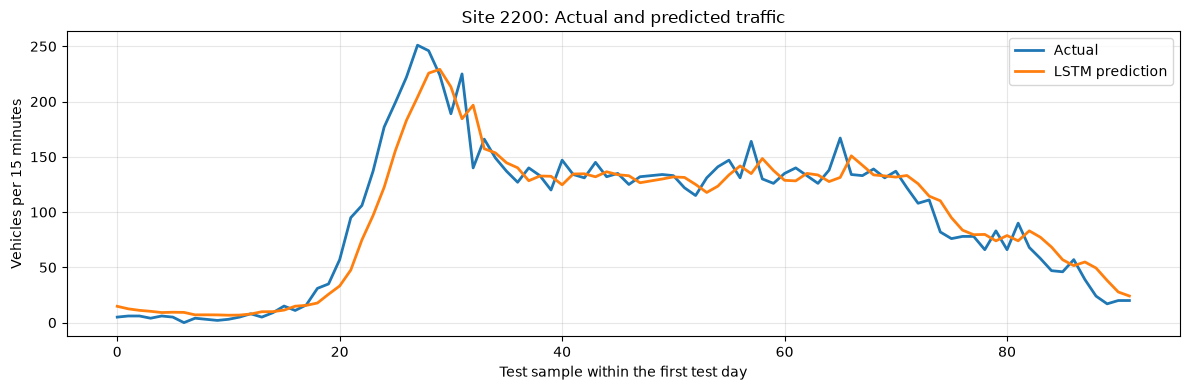

In [45]:
import matplotlib.pyplot as plt

plot_key = (2200, "MAROONDAH_HWY E of UNION_RD")
actual_values, predicted_values = test_predictions[plot_key]

plt.figure(figsize=(12, 4))
plt.plot(actual_values[:92], label="Actual", linewidth=2)
plt.plot(predicted_values[:92], label="LSTM prediction", linewidth=2)
plt.xlabel("Test sample within the first test day")
plt.ylabel("Vehicles per 15 minutes")
plt.title("Site 2200: Actual and predicted traffic")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
import json
from pathlib import Path

model_folder = project_dir / "saved_models"
model_folder.mkdir(parents=True, exist_ok=True)

model_metadata = []

for index, ((site, location), model_data) in enumerate(
    sorted(traffic_models.items()), start=1
):
    site_model, minimum, scale_range = model_data
    filename = f"model_{index:03d}_{site}.keras"

    site_model.save(model_folder / filename)

    model_metadata.append({
        "site": int(site),
        "location": location,
        "filename": filename,
        "minimum": float(minimum),
        "scale_range": float(scale_range),
        "window_size": 4,
    })

metadata_path = model_folder / "metadata.json"
metadata_path.write_text(
    json.dumps(model_metadata, indent=2),
    encoding="utf-8",
)

print(f"Saved models: {len(model_metadata)}")
print("Folder:", model_folder)

Saved models: 8
Folder: /Users/chinkh/Swinburne/COS30019/COS30019/saved_models


In [47]:
from tensorflow.keras.models import load_model

saved_metadata = json.loads(
    metadata_path.read_text(encoding="utf-8")
)

loaded_models = {}

for item in saved_metadata:
    key = (item["site"], item["location"])

    loaded_models[key] = (
        load_model(
            model_folder / item["filename"],
            compile=False,
        ),
        item["minimum"],
        item["scale_range"],
    )

assert set(loaded_models) == set(traffic_models)

print(f"Loaded models: {len(loaded_models)}")
print("PASS: All model locations restored")

Loaded models: 8
PASS: All model locations restored


In [48]:
check_key = (2200, "MAROONDAH_HWY E of UNION_RD")

X_check, _, dates_check = make_location_samples(*check_key)
check_windows = X_check[
    dates_check.normalize() == pd.Timestamp("2006-10-25")
]
check_input = check_windows[0:1]

original_model, original_min, original_range = traffic_models[check_key]
loaded_model, loaded_min, loaded_range = loaded_models[check_key]

original_prediction = (
    original_model.predict(
        (check_input - original_min) / original_range,
        verbose=0,
    ).item() * original_range + original_min
)

loaded_prediction = (
    loaded_model.predict(
        (check_input - loaded_min) / loaded_range,
        verbose=0,
    ).item() * loaded_range + loaded_min
)

assert np.isclose(
    original_prediction,
    loaded_prediction,
    rtol=1e-5,
    atol=1e-4,
)

print(f"Original prediction: {original_prediction:.4f}")
print(f"Loaded prediction:   {loaded_prediction:.4f}")
print("PASS: Saved model reproduces the prediction")

# Let the existing prediction function use the loaded models.
traffic_models = loaded_models

Original prediction: 14.7701
Loaded prediction:   14.7701
PASS: Saved model reproduces the prediction


In [49]:
import json

# Save the current road network.
roads.to_csv(project_dir / "roads.csv", index=False)

# Save defaults used by the application.
default_config = {
    "date": "2006-10-25",
    "target_slot": 4,
    "origin": 970,
    "destination": 3682,
    "max_routes": 5,
}

(project_dir / "config.json").write_text(
    json.dumps(default_config, indent=2),
    encoding="utf-8",
)

print("Saved roads:", len(roads))
print("Created roads.csv and config.json")

Saved roads: 7
Created roads.csv and config.json


In [50]:
import sys
from pathlib import Path

project_dir = Path("/Users/chinkh/Swinburne/COS30019/COS30019")
sys.path.insert(0, str(project_dir))

# Import the class from the saved Python file.
from traffic_runtime import TrafficSystem

system_check = TrafficSystem()
routes_check = system_check.query(
    origin=970,
    destination=3682,
    date_text="2006-10-25",
    target_slot=4,
)

for rank, (path, seconds) in enumerate(routes_check, start=1):
    print(
        f"{rank}. {' → '.join(map(str, path))} "
        f"| {seconds:.2f} seconds"
    )

1. 970 → 2000 → 3682 | 262.20 seconds
2. 970 → 2000 → 4043 → 4040 → 3804 → 3682 | 785.40 seconds


In [54]:
import sys
import importlib
from pathlib import Path

# Locate the project and load the latest runtime code.
project_dir = Path("/Users/chinkh/Swinburne/COS30019/COS30019")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

import traffic_runtime
importlib.reload(traffic_runtime)

system_check = traffic_runtime.TrafficSystem()

print(f"Loaded models: {len(system_check.models)}")
print(f"Roads: {len(system_check.roads)}")
print(f"Stations: {len(system_check.stations)}")

# Check every search option using the same query.
for method in ["TOP5", "BFS", "AS", "CUS1", "CUS2"]:
    routes = system_check.query_selected(
        origin=970,
        destination=3682,
        date_text="2006-10-25",
        target_slot=4,
        method=method,
        limit=5,
    )

    print(f"\n{method}: {len(routes)} route(s)")

    for path, seconds in routes:
        route_text = " → ".join(map(str, path))
        print(f"  {route_text} | {seconds:.2f} seconds")

Loaded models: 8
Roads: 7
Stations: 6

TOP5: 2 route(s)
  970 → 2000 → 3682 | 262.20 seconds
  970 → 2000 → 4043 → 4040 → 3804 → 3682 | 785.40 seconds

BFS: 1 route(s)
  970 → 2000 → 3682 | 262.20 seconds

AS: 1 route(s)
  970 → 2000 → 3682 | 262.20 seconds

CUS1: 1 route(s)
  970 → 2000 → 3682 | 262.20 seconds

CUS2: 1 route(s)
  970 → 2000 → 3682 | 262.20 seconds


In [5]:
import json
import shutil
from pathlib import Path

import pandas as pd

project_dir = Path(
    "/Users/chinkh/Swinburne/COS30019/COS30019"
)
roads_path = project_dir / "roads.csv"
backup_path = project_dir / "roads_before_north_split.csv"

# Confirm the north-side model is available.
metadata = json.loads(
    (project_dir / "saved_models" / "metadata.json")
    .read_text(encoding="utf-8")
)

north_model = next(
    (
        item for item in metadata
        if int(item["site"]) == 3685
        and item["location"] == "WARRIGAL_RD N of HIGHBURY_RD"
    ),
    None,
)

if north_model is None:
    raise ValueError("The saved north-side model is missing.")

if not (
    project_dir / "saved_models" / north_model["filename"]
).is_file():
    raise FileNotFoundError("The north-side model file is missing.")

roads = pd.read_csv(roads_path)

if not backup_path.exists():
    shutil.copy2(roads_path, backup_path)

# Split only the northbound prototype link.
# Leave the existing reverse link unchanged for now.
old_link = (
    (roads["source"] == 970)
    & (roads["destination"] == 2000)
)
roads = roads.loc[~old_link].copy()

# Straight-line distance estimates, not measured road distances.
new_links = pd.DataFrame(
    [
        (970, 3685, 1.395,
         "WARRIGAL_RD N of HIGH STREET_RD"),
        (3685, 2000, 0.333,
         "WARRIGAL_RD N of HIGHBURY_RD"),
    ],
    columns=[
        "source",
        "destination",
        "distance_km",
        "traffic_location",
    ],
)

roads = pd.concat([roads, new_links], ignore_index=True)
roads = roads.drop_duplicates(
    subset=["source", "destination"],
    keep="last",
)
roads.to_csv(roads_path, index=False)

print("Roads saved:", len(roads))
display(roads)

Roads saved: 8


,source,destination,distance_km,traffic_location
0,2000,3682,1.650,WARRIGAL_RD N of TOORAK_RD
1,2000,970,1.720,WARRIGAL_RD S of BURWOOD_HWY
2,2000,4043,3.670,TOORAK_RD W of WARRIGAL_RD
3,4043,4040,1.570,BURKE_RD N of TOORAK_RD
4,4040,3804,0.600,RIVERSDALE_RD E of BURKE_RD
5,3804,3682,3.030,RIVERSDALE_RD E of TRAFALGAR_RD
6,970,3685,1.395,WARRIGAL_RD N of HIGH STREET_RD
7,3685,2000,0.333,WARRIGAL_RD N of HIGHBURY_RD


## 📊 Dataset Overview and Feature Selection

This dataset contains traffic flow observations collected from SCATS (Sydney Coordinated Adaptive Traffic System) sensors. Each row represents traffic measurements recorded at a specific location on a given date.

---

### 🔍 Raw Data Structure

The dataset consists of several groups of variables:

- **Location-related attributes**
  - `SCATS Number`
  - `Location`
  - `NB_LATITUDE`, `NB_LONGITUDE`

- **Administrative / metadata fields**
  - `CD_MELWAY`
  - `HF VicRoads Internal`
  - `VR Internal Stat`
  - `VR Internal Loc`
  - `NB_TYPE_SURVEY`

- **Temporal attribute**
  - `Date`

- **Traffic volume measurements**
  - `V00` to `V95`  
    (96 intervals representing 15-minute traffic counts over a 24-hour period)

---

### ⚠️ Redundant and Irrelevant Features

Several columns are either constant or serve only as identifiers/metadata. These include:

- `CD_MELWAY`
- `HF VicRoads Internal`
- `VR Internal Stat`
- `VR Internal Loc`
- `NB_TYPE_SURVEY`

These variables do not provide meaningful information for time-series analysis and can be removed.

---

### ✅ Essential Features

For traffic flow analysis and time-series modeling, only the following variables are required:

- `Location` → identifies the monitoring point  
- `Date` → defines the temporal order  
- `V00–V95` → traffic volume measurements (core signal)

---

### 🧠 Data Interpretation

Each row represents:

- One **day**
- At a specific **location**
- With **96 time intervals** (15-minute resolution)

This means the dataset can be treated as:

- A **daily time series per location**, or  
- A **high-frequency time series** after reshaping

---

### ✂️ Simplified Dataset Schema

After removing irrelevant columns, the dataset can be reduced to:


## 📍 Selecting a Single Location for Time-Series Analysis

Before performing any time-series transformation, it is essential to **select a single location** from the dataset.

---

### ❗ Why is this necessary?

The dataset contains traffic data from multiple locations. Each location represents a **different traffic behavior**, influenced by factors such as:

- Road type
- Traffic signals
- Surrounding environment
- Daily traffic patterns

Combining multiple locations into a single time series would result in:

- Mixed patterns
- Inconsistent trends
- Poor model performance

---

### 🧠 Key Idea

Time-series models (e.g., ARIMA/SARIMA) assume that the data comes from a **single, consistent source over time**.

Therefore, we must isolate one location to ensure:

- Temporal consistency  
- Meaningful seasonal patterns  
- Reliable forecasting results  

---

## 🎯 Defining Features (X) and Target Variable (y)

After selecting a single location, the next step is to define the input features (**X**) and the target variable (**y**) for analysis.

---

### 🧠 Conceptual Understanding

In this dataset:

- The columns `V00` to `V95` represent **traffic volume measurements** at 15-minute intervals throughout a day.
- These values form the **core signal** of the dataset.

Depending on the modeling objective, we structure the data as follows:

---

### ✅ Feature and Target Definition

- **X (Features):**
  - Time-related information (to be constructed)
  - Example:
    - Time index (00:00, 00:15, ..., 23:45)
    - Datetime (combination of `Date` and time interval)

- **y (Target Variable):**
  - Traffic volume values from `V00` to `V95`

---

### ⚠️ Important Note

At this stage, the dataset is still in **wide format**, where:

- Each row contains 96 traffic values (`V00–V95`)
- Time is not yet explicitly represented as a variable

This means:

- `X` is **not fully defined yet**
- We must first transform the dataset into a proper time-based structure

---

### 🔄 What Happens Next?

To properly define **X and y**, we need to:

1. Convert the dataset from **wide format to long format**
2. Generate a **time index** for each interval
3. Combine `Date` with time intervals to form a **Datetime feature**

After this transformation:

- **X** → Datetime (time axis)  
- **y** → Traffic volume  

---

### 📌 Summary

At this stage:

- `y` is already available → traffic volume (`V00–V95`)  
- `X` will be constructed → from time expansion in the next step  

This prepares the dataset for time-series modeling such as ARIMA or SARIMA.

## 📈 Final Definition of X and y for Modeling

After transforming the dataset into a continuous time series, we now have a clear structure for defining the input features (**X**) and the target variable (**y**).

---

### ✅ Available Information

At this stage, the dataset contains:

- `datetime` → precise timestamp (combined date and 15-minute intervals)  
- `traffic` → observed traffic volume  

Optionally, additional time-based features may also be available:

- Hour of day  
- Day of week  
- Month  

---

### 🎯 Feature and Target Specification

- **X (Features):**
  - `datetime` (as the time index), and/or derived temporal features such as:
    - Hour  
    - Day of week  
    - Month  

- **y (Target Variable):**
  - `traffic` (traffic volume)

---

### 🧠 Interpretation

The problem can now be formulated as:

> Predicting traffic volume (**y**) as a function of time (**X**)

This structure is suitable for:

- Time-series models (e.g., ARIMA, SARIMA)  
- Regression-based approaches using temporal features  

---

### 🚀 Modeling Readiness

The dataset is now:

- Cleaned and simplified  
- Properly indexed by time  
- Structured with clearly defined **X** and **y**

This allows us to proceed with building a **regression or forecasting model** for traffic prediction at the selected location.

---

### 📌 Summary

- Time information has been fully constructed → `datetime`  
- Target variable is defined → `traffic`  
- The dataset is now ready for **modeling and evaluation**

in this case, the error for the regression tree in predicting the traffic for the 1st location is 33%. the lower the NRMSE, the better the model.